# Task 2b - Custom CNN v2 (latest `custom-complex-cnn`) on the shared pipeline

Recipe from the latest commit of `custom-complex-cnn` (`c02b33a`, `results/custom_cnn/02_custom_cnn_.ipynb`),
kept as it is: ReLU everywhere, a stride-2 stem convolution without BatchNorm, five residual
squeeze-and-excitation blocks (64, 128, 128, 256, 256 filters; convolutions with bias, BatchNorm after each
3x3 convolution, 1x1 projection shortcut without BatchNorm), global average pooling, Dropout(0.4),
Dense(128, ReLU), Dense(4, softmax). Cross-entropy without label smoothing, Adam 1e-3, batch 32, up to 50
epochs, ReduceLROnPlateau on val_loss (x0.5, patience 4, min 1e-6), early stopping on val_loss (patience 10)
with the best epoch restored.

Two mechanical differences, neither changes the recipe: the branch feeds integer labels to
`sparse_categorical_crossentropy`, the shared pipeline feeds one-hot labels to `categorical_crossentropy`
(the same loss); and the best val_loss epoch is restored from a checkpoint instead of by
`EarlyStopping(restore_best_weights=True)`.

**Data.** Unlike the branch (Kaggle `data/split.csv`, images stretched to 224x224, no augmentation), this run
uses the shared pipeline of `src/data.py`: `data/split_aspect.csv`, square crop from the raw image (random on
train, center on val/test) resized to 224x224, train-only affine/flip/brightness/contrast augmentation, and
aspect-balanced sampling. The run of the branch notebook itself, on its own data, is in
`results/custom_cnn_v2_original_pipeline/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import keras
import pandas as pd
from keras import layers

import config
from src import data, experiment

experiment.setup()
frames, datasets = data.load_datasets()
{split: len(frame) for split, frame in frames.items()}

I0000 00:00:1791614506.387981   12353 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791614506.441014   12353 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791614507.842045   12353 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | policy: float32


I0000 00:00:1791614509.826941   12353 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3618 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


{'train': 3200, 'val': 800, 'test': 800}

## Model (as in `c02b33a`)

In [2]:
def res_block(x, filters, stride=1):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    # squeeze-and-excitation
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(filters // 16, activation="relu")(se)
    se = layers.Dense(filters, activation="sigmoid")(se)
    se = layers.Reshape((1, 1, filters))(se)
    x = layers.Multiply()([x, se])
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride)(shortcut)
    x = layers.Add()([x, shortcut])
    return layers.Activation("relu")(x)


inputs = layers.Input(shape=(config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
x = layers.Rescaling(1 / 255)(inputs)            # the branch divides by 255 in its loader
x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(x)
x = res_block(x, 64)                # 112x112
x = res_block(x, 128, stride=2)     # 56x56
x = res_block(x, 128)
x = res_block(x, 256, stride=2)     # 28x28
x = res_block(x, 256)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(len(config.CLASS_NAMES), activation="softmax")(x)
model = keras.Model(inputs, outputs, name="custom_cnn_v2")

experiment.compile_model(model, keras.optimizers.Adam(1e-3))
print(f"{model.count_params():,} parameters")

2,743,736 parameters


## Train and evaluate

In [3]:
fit_info = experiment.fit(model, "custom_cnn_v2", datasets, epochs=50, monitor="val_loss", early_stopping=10,
                          reduce_lr=dict(factor=0.5, patience=4, min_lr=1e-6))

Epoch 1/50


I0000 00:00:1791614511.088038   12353 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


I0000 00:00:1791614518.502670   12419 cuda_dnn.cc:461] Loaded cuDNN version 92000


I0000 00:00:1791614581.028819   12515 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 57609256724699872
/home/minhquang/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 - 77s - 769ms/step - accuracy: 0.6634 - f1: 0.6544 - loss: 0.8538 - val_accuracy: 0.2500 - val_f1: 0.1000 - val_loss: 3.7999 - learning_rate: 0.0010


...

I0000 00:00:1791616949.023544   12515 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 57609256724699872


100/100 - 45s - 446ms/step - accuracy: 0.9472 - f1: 0.9428 - loss: 0.1379 - val_accuracy: 0.9388 - val_f1: 0.9390 - val_loss: 0.1727 - learning_rate: 3.1250e-05


Epoch 50/50


I0000 00:00:1791616993.198080   12515 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 57609256724699872


100/100 - 47s - 466ms/step - accuracy: 0.9500 - f1: 0.9477 - loss: 0.1313 - val_accuracy: 0.9388 - val_f1: 0.9391 - val_loss: 0.1725 - learning_rate: 3.1250e-05


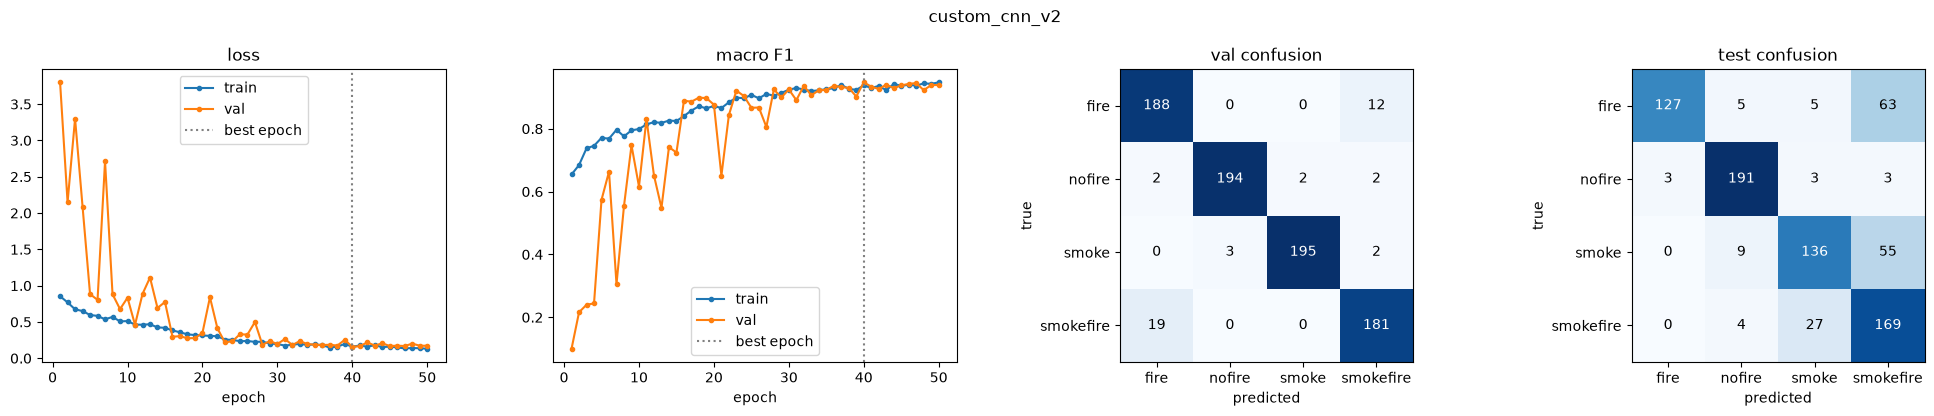

task                                2 custom CNN v2 (c02b33a)
run                                             custom_cnn_v2
trainable_params                                      2740408
total_params                                          2743736
best_epoch                                                 40
epochs_run                                                 50
train_minutes                                            41.5
val_acc                                                0.9475
val_f1                                               0.947713
test_acc                                              0.77875
test_f1                                              0.781658
test_f1_fire                                         0.769697
test_f1_nofire                                       0.933985
test_f1_smoke                                        0.733154
test_f1_smokefire                                    0.689796
test_smokefire_as_smoke                                    27
test_fir

In [4]:
settings = {"source": "custom-complex-cnn c02b33a, results/custom_cnn/02_custom_cnn_.ipynb", "input": "224, /255",
            "optimizer": "Adam 1e-3", "loss": "categorical cross-entropy (one-hot; = sparse CE)", "epochs": 50,
            "early_stopping": "val_loss, patience 10, best epoch restored",
            "reduce_lr": "val_loss x0.5, patience 4, min 1e-6", "selection": "val_loss"}
experiment.evaluate(model, "custom_cnn_v2", "2 custom CNN v2 (c02b33a)", frames, datasets, fit_info, settings)

## All runs so far

In [5]:
board = pd.read_csv(config.RESULTS_DIR / "leaderboard.csv")
board[["task", "run", "trainable_params", "best_epoch", "val_acc", "val_f1", "test_acc", "test_f1",
       "test_f1_smokefire", "test_smokefire_as_smoke", "test_fire_as_smokefire"]].round(4)

,task,run,trainable_params,best_epoch,val_acc,val_f1,test_acc,test_f1,test_f1_smokefire,test_smokefire_as_smoke,test_fire_as_smokefire
0,1 basic NN,basic_nn,3147012,28,0.6863,0.6792,0.6050,0.6088,0.4637,107,50
1,2 custom CNN,custom_cnn,2738340,46,0.9563,0.9564,0.7625,0.7648,0.6845,19,72
2,3 frozen backbone,frozen_xception,1052164,15,0.8988,0.8990,0.7388,0.7462,0.6071,48,72
3,3 frozen backbone,frozen_resnet50,1052164,11,0.9463,0.9463,0.7775,0.7840,0.6473,44,68
4,4 fine-tune: stage 1 (frozen),ft_stage1_xception,525572,6,0.8875,0.8884,0.7137,0.7195,0.5637,61,82
5,4 fine-tune: stage 2 top,ft_top_xception,7301236,19,0.9375,0.9375,0.7588,0.7660,0.6164,52,68
6,4 fine-tune: stage 2 all,ft_all_xception,21277996,19,0.9688,0.9688,0.7762,0.7828,0.6615,28,74
7,4 fine-tune: stage 1 (frozen),ft_stage1_resnet50,525572,8,0.9463,0.9460,0.7800,0.7859,0.6398,45,64
8,4 fine-tune: stage 2 top,ft_top_resnet50,15479044,7,0.9700,0.9700,0.7750,0.7812,0.6602,29,66
9,4 fine-tune: stage 2 all,ft_all_resnet50,24007044,5,0.9750,0.9750,0.7788,0.7858,0.6477,41,69
